# ML 03 - Classification: Predicting Late Deliveries in a Health-Commodity Supply Chain

**Objective:** predict, at the time a shipment is planned, whether it will be delivered **later than its scheduled delivery date**, so planners can expedite, add buffer stock or re-route the at-risk orders.

**Dataset:** USAID/PEPFAR *Supply Chain Shipment Pricing Data* (SCMS Delivery History), 10,324 shipment line items, 2006-2015 - public data, no login required.

**Validation design**
- Target = `Delivered to Client Date > Scheduled Delivery Date` (built from two columns; **neither** is used as a feature).
- Chronological split: oldest 80% of shipments (by scheduled date) = development set, newest 20% = untouched **temporal test set**.
- Model selection with **stratified 5-fold CV** on the development set only; decision threshold chosen on out-of-fold predictions only.
- Baselines (prior / majority), leakage audit, shuffled-label check, bootstrap CI.

In [1]:
import warnings, os
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict, cross_validate
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, confusion_matrix, precision_recall_curve,
                             roc_curve, fbeta_score, precision_score, recall_score, brier_score_loss)
sns.set_theme(style="whitegrid")
OUT = Path("."); SEED = 42
RAW = pd.read_csv("SCMS_Delivery_History_Dataset.csv", encoding="utf-8-sig")
print(RAW.shape)

(10324, 33)


## 1. Target construction and data audit
Dates arrive in two formats (`d-Mon-yy` for scheduled/delivered, `m/d/yy` for PO date) plus text placeholders (`N/A - From RDC`, `Date Not Captured`, `Pre-PQ Process`). Placeholders become missing values.

In [2]:
MON = {m: i + 1 for i, m in enumerate(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])}
def parse_dmy(x):
    try:
        d, m, y = str(x).split("-"); return pd.Timestamp(2000 + int(y), MON[m], int(d))
    except Exception:
        return pd.NaT
df = RAW.copy()
df["sched"] = df["Scheduled Delivery Date"].map(parse_dmy)
df["deliv"] = df["Delivered to Client Date"].map(parse_dmy)
df["po_date"] = pd.to_datetime(df["PO Sent to Vendor Date"], format="%m/%d/%y", errors="coerce")
df["pq_date"] = pd.to_datetime(df["PQ First Sent to Client Date"], format="%m/%d/%y", errors="coerce")
print("unparsed scheduled / delivered dates:", int(df.sched.isna().sum()), "/", int(df.deliv.isna().sum()))
print("scheduled range:", df.sched.min().date(), "->", df.sched.max().date())
df["late"] = (df["deliv"] > df["sched"]).astype(int)
df["days_late"] = (df["deliv"] - df["sched"]).dt.days
print("\nLate rate: %.2f%% (%d of %d)" % (100 * df.late.mean(), df.late.sum(), len(df)))
print("days late among late shipments:", df.loc[df.late == 1, "days_late"].describe().round(1).to_dict())
print("duplicated rows:", int(df.duplicated().sum()), "| duplicated ID:", int(df["ID"].duplicated().sum()))
print("\nLate rate by year of scheduled date:")
display(df.groupby(df.sched.dt.year)["late"].agg(["mean", "size"]).round(3).T)

unparsed scheduled / delivered dates: 0 / 0
scheduled range: 2006-05-02 -> 2015-12-31

Late rate: 11.49% (1186 of 10324)
days late among late shipments: {'count': 1186.0, 'mean': 21.4, 'std': 28.5, 'min': 1.0, '25%': 5.0, '50%': 12.0, '75%': 24.8, 'max': 192.0}
duplicated rows: 0 | duplicated ID: 0

Late rate by year of scheduled date:


sched,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015
mean,0.0,0.021,0.013,0.036,0.159,0.235,0.079,0.179,0.154,0.118
size,65.0,672.000,1029.000,1253.000,1204.000,1011.000,1273.000,1272.000,1528.000,1017.000


## 2. Features (decision time = shipment planned)
Only information that exists when the order is placed and scheduled:
- **Categorical:** country, fulfilment route (Direct Drop / From RDC), vendor INCO term, shipment mode, product group & sub-classification, vendor, dosage form, brand, first-line designation, managed-by. Rare categories (<20 rows) are grouped by the encoder.
- **Numeric:** log quantity, log line-item value, pack price, unit price, units per pack, scheduled year/month, **planned lead time** (scheduled date - PO sent date; missing for RDC shipments) and **PQ-to-schedule window** (days between price quote and schedule).

**Deliberately excluded:** `Delivered to Client Date` and `Delivery Recorded Date` (outcomes), `ID / PO / ASN-DN` identifiers, and **`Weight` / `Freight Cost`**: they are often entered after shipment (or by reference text such as "See DN-304"), so they could leak outcome information. A leakage audit below quantifies the effect of adding them.

In [3]:
for c in ["Shipment Mode", "Dosage Form", "Brand", "Sub Classification", "Vendor", "Country", "Managed By", "Fulfill Via", "Vendor INCO Term", "Product Group", "First Line Designation"]:
    df[c] = df[c].fillna("Unknown").astype(str)
df["log_qty"] = np.log1p(df["Line Item Quantity"])
df["log_value"] = np.log1p(df["Line Item Value"])
df["sched_year"] = df.sched.dt.year; df["sched_month"] = df.sched.dt.month
df["planned_lead_days"] = (df.sched - df.po_date).dt.days
df["pq_window_days"] = (df.sched - df.pq_date).dt.days
CAT = ["Country", "Fulfill Via", "Vendor INCO Term", "Shipment Mode", "Product Group", "Sub Classification", "Vendor",
       "Dosage Form", "Brand", "First Line Designation", "Managed By"]
NUM = ["log_qty", "log_value", "Pack Price", "Unit Price", "Unit of Measure (Per Pack)", "sched_year", "sched_month",
       "planned_lead_days", "pq_window_days"]
print("negative planned lead times:", int((df.planned_lead_days < 0).sum()), "| missing planned_lead_days: %.1f%%" % (100 * df.planned_lead_days.isna().mean()))
# chronological split
df = df.sort_values(["sched", "ID"]).reset_index(drop=True)
n_dev = int(0.8 * len(df))
dev, test = df.iloc[:n_dev].copy(), df.iloc[n_dev:].copy()
print("dev: %d rows (%s -> %s), late %.2f%% | test: %d rows (%s -> %s), late %.2f%%" % (
    len(dev), dev.sched.min().date(), dev.sched.max().date(), 100 * dev.late.mean(),
    len(test), test.sched.min().date(), test.sched.max().date(), 100 * test.late.mean()))
Xd, yd, Xt, yt = dev[CAT + NUM], dev["late"].values, test[CAT + NUM], test["late"].values

negative planned lead times: 4 | missing planned_lead_days: 55.5%
dev: 8259 rows (2006-05-02 -> 2014-05-02), late 11.13% | test: 2065 rows (2014-05-02 -> 2015-12-31), late 12.93%


In [4]:
def make_pre(scale=False, num=NUM, cat=CAT):
    num_pipe = [("imp", SimpleImputer(strategy="median", add_indicator=True))] + ([("sc", StandardScaler())] if scale else [])
    return ColumnTransformer([("num", Pipeline(num_pipe), num),
                              ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False), cat)])
models = {
    "Baseline (class prior)": Pipeline([("pre", make_pre()), ("m", DummyClassifier(strategy="prior"))]),
    "Logistic Regression": Pipeline([("pre", make_pre(True)), ("m", LogisticRegression(max_iter=3000, class_weight="balanced", C=0.1))]),
    "Random Forest": Pipeline([("pre", make_pre()), ("m", RandomForestClassifier(n_estimators=400, min_samples_leaf=3, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED))]),
    "Gradient Boosting (HistGB)": Pipeline([("pre", make_pre()), ("m", HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_leaf_nodes=15, l2_regularization=1.0, random_state=SEED))]),
}

## 3. Model comparison - stratified 5-fold CV on the development set
Hyper-parameters are fixed a-priori (modest regularisation, no search on the test set). `class_weight` handles the class imbalance where available. Metrics are computed per fold and averaged (mean +/- std).

In [5]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
rows = []
for name, pipe in models.items():
    r = cross_validate(pipe, Xd, yd, cv=cv, scoring={"roc": "roc_auc", "ap": "average_precision"}, n_jobs=1)
    rows.append({"Model": name, "ROC-AUC": r["test_roc"].mean(), "ROC-AUC std": r["test_roc"].std(),
                 "PR-AUC": r["test_ap"].mean(), "PR-AUC std": r["test_ap"].std()})
cvres = pd.DataFrame(rows).set_index("Model")
print("Late rate in dev set (= PR-AUC of a random model): %.3f" % yd.mean())
display(cvres.round(3)); cvres.round(4).to_csv(OUT / "cv_model_comparison.csv")

Late rate in dev set (= PR-AUC of a random model): 0.111


,ROC-AUC,ROC-AUC std,PR-AUC,PR-AUC std
Model,,,,
Baseline (class prior),0.500,0.000,0.111,0.000
Logistic Regression,0.810,0.009,0.296,0.016
Random Forest,0.886,0.009,0.480,0.029
Gradient Boosting (HistGB),0.896,0.011,0.554,0.042


## 4. Decision threshold from out-of-fold predictions
A missed late delivery (false negative) is costlier than an unnecessary expedite check (false positive), so I choose the threshold that maximises **F2** (recall weighted 2x precision) on the *out-of-fold* predictions of the development set - the test set plays no part in this choice.

Best model by CV PR-AUC: Gradient Boosting (HistGB)


Threshold maximising F2 on OOF predictions: 0.13 (F2 = 0.653)
OOF at threshold: precision 0.343 | recall 0.844


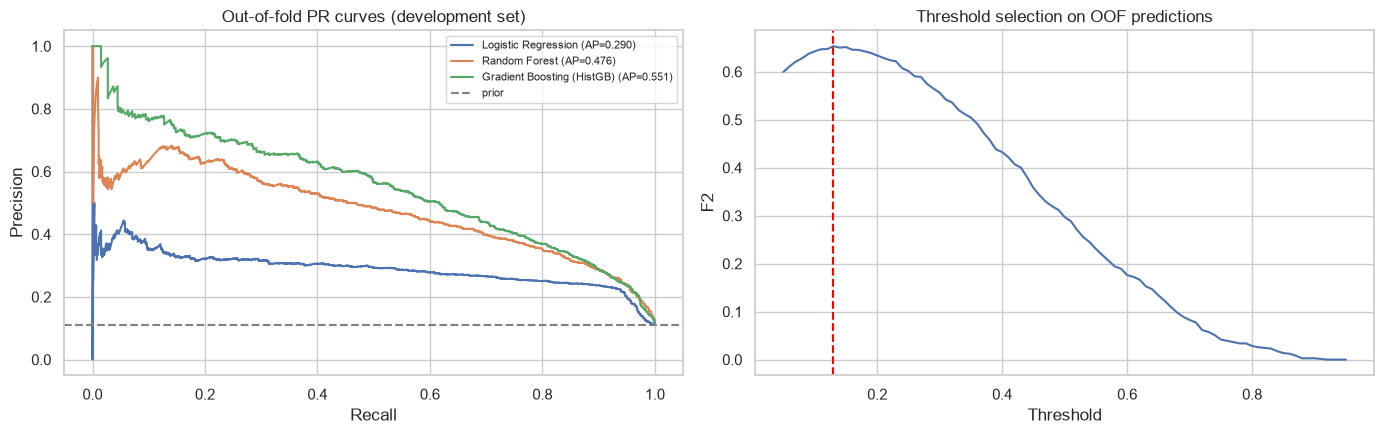

In [6]:
best_name = cvres.drop(index="Baseline (class prior)")["PR-AUC"].idxmax()
print("Best model by CV PR-AUC:", best_name)
oof = {n: cross_val_predict(models[n], Xd, yd, cv=cv, method="predict_proba")[:, 1] for n in models if n != "Baseline (class prior)"}
ths = np.linspace(0.05, 0.95, 91)
f2 = [fbeta_score(yd, oof[best_name] >= t, beta=2) for t in ths]
THR = float(ths[int(np.argmax(f2))])
print("Threshold maximising F2 on OOF predictions: %.2f (F2 = %.3f)" % (THR, max(f2)))
print("OOF at threshold: precision %.3f | recall %.3f" % (precision_score(yd, oof[best_name] >= THR), recall_score(yd, oof[best_name] >= THR)))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for n, p in oof.items():
    pr, rc, _ = precision_recall_curve(yd, p); ax[0].plot(rc, pr, label=f"{n} (AP={average_precision_score(yd, p):.3f})")
ax[0].axhline(yd.mean(), ls="--", c="grey", label="prior"); ax[0].set_xlabel("Recall"); ax[0].set_ylabel("Precision"); ax[0].set_title("Out-of-fold PR curves (development set)"); ax[0].legend(fontsize=8)
ax[1].plot(ths, f2); ax[1].axvline(THR, c="red", ls="--"); ax[1].set_xlabel("Threshold"); ax[1].set_ylabel("F2"); ax[1].set_title("Threshold selection on OOF predictions")
plt.tight_layout(); plt.savefig(OUT / "01_cv_pr_curves_threshold.png", dpi=130); plt.show()

## 5. Final evaluation on the chronological test set
All models are refit on the full development set and evaluated once on the newest 20% of shipments. The test period is later than anything in training, so any drift counts against the model.

Test late rate (= random PR-AUC): 0.129


,ROC-AUC,PR-AUC,Brier
Model,,,
Baseline (class prior),0.500,0.129,0.113
Logistic Regression,0.781,0.323,0.226
Random Forest,0.829,0.369,0.117
Gradient Boosting (HistGB),0.830,0.380,0.098



Gradient Boosting (HistGB) @ threshold 0.13: TN=1274 FP=524 FN=34 TP=233
precision 0.308 | recall 0.873 | F2 0.638 | flagged 36.7% of shipments


95% bootstrap CI - ROC-AUC [0.804, 0.854] | PR-AUC [0.330, 0.436]


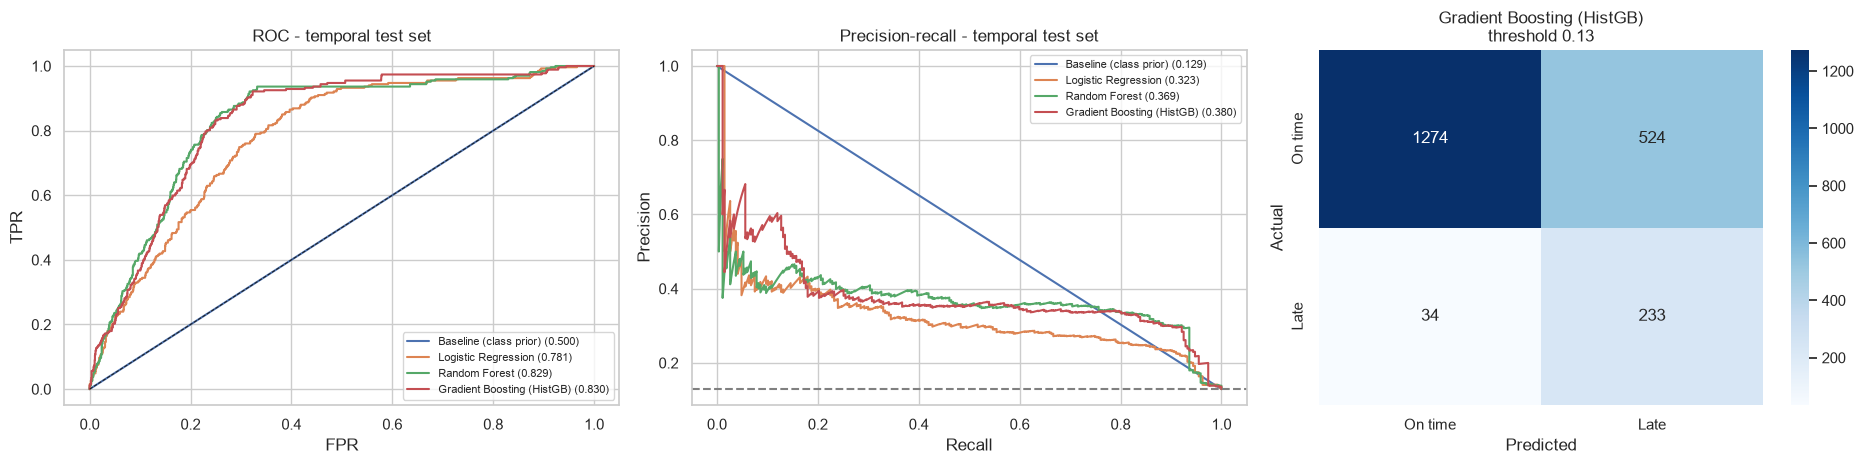

In [7]:
fitted = {n: p.fit(Xd, yd) for n, p in models.items()}
rows, probs = [], {}
for n, p in fitted.items():
    pr = p.predict_proba(Xt)[:, 1]; probs[n] = pr
    rows.append({"Model": n, "ROC-AUC": roc_auc_score(yt, pr), "PR-AUC": average_precision_score(yt, pr), "Brier": brier_score_loss(yt, pr)})
testres = pd.DataFrame(rows).set_index("Model")
print("Test late rate (= random PR-AUC): %.3f" % yt.mean())
display(testres.round(3)); testres.round(4).to_csv(OUT / "test_model_comparison.csv")

# confusion matrix for the CV-selected model at the OOF-chosen threshold
pb = probs[best_name]; pred = (pb >= THR).astype(int)
tn, fp, fn, tp = confusion_matrix(yt, pred).ravel()
print(f"\n{best_name} @ threshold {THR:.2f}: TN={tn} FP={fp} FN={fn} TP={tp}")
print("precision %.3f | recall %.3f | F2 %.3f | flagged %.1f%% of shipments" % (precision_score(yt, pred), recall_score(yt, pred), fbeta_score(yt, pred, beta=2), 100 * pred.mean()))
# bootstrap CI
rng = np.random.default_rng(SEED); aucs, aps = [], []
for _ in range(500):
    i = rng.integers(0, len(yt), len(yt))
    if yt[i].min() == yt[i].max(): continue
    aucs.append(roc_auc_score(yt[i], pb[i])); aps.append(average_precision_score(yt[i], pb[i]))
print("95%% bootstrap CI - ROC-AUC [%.3f, %.3f] | PR-AUC [%.3f, %.3f]" % (*np.percentile(aucs, [2.5, 97.5]), *np.percentile(aps, [2.5, 97.5])))

fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
for n, p in probs.items():
    fpr, tpr, _ = roc_curve(yt, p); ax[0].plot(fpr, tpr, label=f"{n} ({roc_auc_score(yt, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=.7); ax[0].set_title("ROC - temporal test set"); ax[0].legend(fontsize=8); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR")
for n, p in probs.items():
    pr_, rc_, _ = precision_recall_curve(yt, p); ax[1].plot(rc_, pr_, label=f"{n} ({average_precision_score(yt, p):.3f})")
ax[1].axhline(yt.mean(), ls="--", c="grey"); ax[1].set_title("Precision-recall - temporal test set"); ax[1].legend(fontsize=8); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
sns.heatmap(confusion_matrix(yt, pred), annot=True, fmt="d", cmap="Blues", ax=ax[2], xticklabels=["On time", "Late"], yticklabels=["On time", "Late"])
ax[2].set_title(f"{best_name}\nthreshold {THR:.2f}"); ax[2].set_xlabel("Predicted"); ax[2].set_ylabel("Actual")
plt.tight_layout(); plt.savefig(OUT / "02_test_roc_pr_confusion.png", dpi=130); plt.show()
out = test[["ID", "Country", "Shipment Mode", "Vendor", "sched", "deliv", "late"]].copy(); out["p_late"] = pb; out["pred_late"] = pred
out.to_csv(OUT / "test_set_predictions.csv", index=False)

### Operating points
The F2 threshold flags a large share of shipments. A planner with limited capacity may prefer to review only the highest-risk X% - the table gives precision / recall / lift on the test set when flagging a fixed share of shipments (the ranking is the same model; no refit).

In [8]:
rows = []
order = np.argsort(-pb)
for share in [0.05, 0.10, 0.20, 0.30, float(pred.mean())]:
    k = int(round(share * len(yt))); sel = order[:k]
    rows.append({"flagged share": share, "flagged shipments": k, "precision": yt[sel].mean(), "recall": yt[sel].sum() / yt.sum(), "lift vs base rate": yt[sel].mean() / yt.mean()})
ops = pd.DataFrame(rows); display(ops.round(3)); ops.round(4).to_csv(OUT / "test_operating_points.csv", index=False)

,flagged share,flagged shipments,precision,recall,lift vs base rate
0,0.050,103,0.447,0.172,3.454
1,0.100,206,0.369,0.285,2.853
2,0.200,413,0.356,0.551,2.753
3,0.300,620,0.340,0.790,2.632
4,0.367,757,0.308,0.873,2.381


## 6. Leakage and sanity audit
1. **Shuffled-label check:** the same pipeline trained on randomly permuted labels must score ~0.5 AUC - confirms there is no hidden path from features to the label.
2. **Random vs chronological validation:** compares stratified-CV AUC with the later-period test AUC - a large gap would indicate temporal drift/optimism.
3. **Suspect columns:** effect of adding `Weight` and `Freight Cost` (possible post-shipment information).
4. **Single-feature sanity:** `planned_lead_days` alone should not predict the label almost perfectly.

In [9]:
best_pipe = lambda: Pipeline(models[best_name].steps)
from sklearn.base import clone
rng = np.random.default_rng(SEED)
shuf = cross_validate(clone(models[best_name]), Xd, rng.permutation(yd), cv=cv, scoring={"roc": "roc_auc", "ap": "average_precision"})
print("1) shuffled labels: CV ROC-AUC %.3f | PR-AUC %.3f (expected ~0.5 / ~%.2f)" % (shuf["test_roc"].mean(), shuf["test_ap"].mean(), yd.mean()))
print("2) CV ROC-AUC %.3f vs test ROC-AUC %.3f for %s" % (cvres.loc[best_name, "ROC-AUC"], testres.loc[best_name, "ROC-AUC"], best_name))

# 3) suspect columns
for c, new in [("Weight (Kilograms)", "weight_kg"), ("Freight Cost (USD)", "freight_usd")]:
    dev[new] = pd.to_numeric(dev[c], errors="coerce"); test[new] = pd.to_numeric(test[c], errors="coerce")
print("   numeric weight available: %.1f%% | numeric freight: %.1f%% of dev rows" % (100 * dev.weight_kg.notna().mean(), 100 * dev.freight_usd.notna().mean()))
NUM2 = NUM + ["weight_kg", "freight_usd"]
pipe2 = Pipeline([("pre", make_pre(False, NUM2)), ("m", clone(models[best_name].steps[-1][1]))])
r2 = cross_validate(pipe2, dev[CAT + NUM2], yd, cv=cv, scoring={"roc": "roc_auc", "ap": "average_precision"})
print("3) + weight/freight: CV ROC-AUC %.3f (vs %.3f) | PR-AUC %.3f (vs %.3f)" % (r2["test_roc"].mean(), cvres.loc[best_name, "ROC-AUC"], r2["test_ap"].mean(), cvres.loc[best_name, "PR-AUC"]))
# 4) single feature
one = dev["planned_lead_days"].fillna(-1).values
print("4) planned_lead_days alone, ROC-AUC (dev): %.3f" % roc_auc_score(yd, one))
audit = {"shuffled_labels_cv_roc_auc": shuf["test_roc"].mean(), "cv_roc_auc": cvres.loc[best_name, "ROC-AUC"], "test_roc_auc": testres.loc[best_name, "ROC-AUC"],
         "with_weight_freight_cv_roc_auc": r2["test_roc"].mean(), "planned_lead_days_alone_roc_auc": roc_auc_score(yd, one)}
pd.Series(audit).round(4).to_csv(OUT / "leakage_audit.csv", header=["value"])

1) shuffled labels: CV ROC-AUC 0.476 | PR-AUC 0.108 (expected ~0.5 / ~0.11)
2) CV ROC-AUC 0.896 vs test ROC-AUC 0.830 for Gradient Boosting (HistGB)
   numeric weight available: 65.4% | numeric freight: 63.6% of dev rows


3) + weight/freight: CV ROC-AUC 0.897 (vs 0.896) | PR-AUC 0.559 (vs 0.554)
4) planned_lead_days alone, ROC-AUC (dev): 0.415


## 7. What drives late deliveries? (permutation importance on the test set)
Permutation importance on the *raw* input columns (each column is shuffled before preprocessing, so one-hot dummies are grouped automatically). Metric = drop in ROC-AUC; 10 repeats.

,feature,auc_drop,std
1,Fulfill Via,0.0784,0.0064
0,Country,0.0274,0.0037
19,pq_window_days,0.0127,0.0055
14,Unit Price,0.0111,0.0050
13,Pack Price,0.0073,0.0017
12,log_value,0.0072,0.0032
18,planned_lead_days,0.0070,0.0025
6,Vendor,0.0060,0.0026
2,Vendor INCO Term,0.0049,0.0037
3,Shipment Mode,0.0029,0.0016


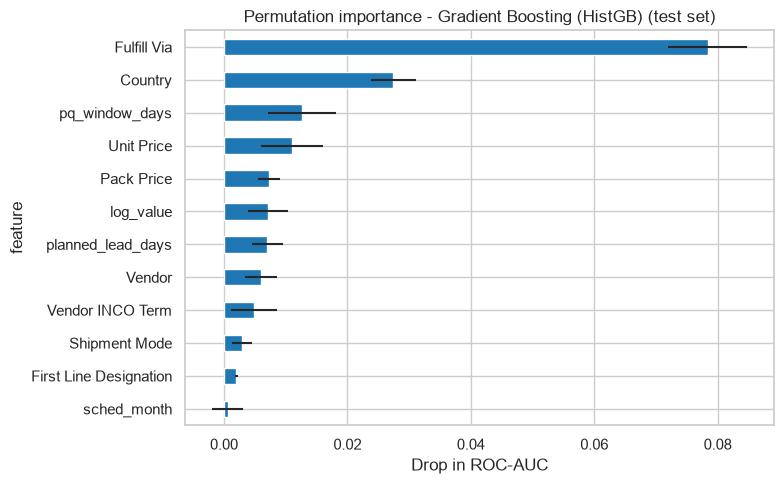


Late rate by Shipment Mode (full data):
                mean  size
Shipment Mode             
Air            0.096  6113
Truck          0.161  2830
Air Charter    0.115   650
Ocean          0.175   371
Unknown        0.011   360

Late rate by Fulfill Via (full data):
              mean  size
Fulfill Via             
From RDC     0.172  5404
Direct Drop  0.053  4920

Late rate by Product Group (full data):
                mean  size
Product Group             
ARV            0.125  8550
HRDT           0.065  1728
ANTM           0.000    22
ACT            0.000    16
MRDT           0.000     8


In [10]:
pi = permutation_importance(fitted[best_name], Xt, yt, scoring="roc_auc", n_repeats=10, random_state=SEED, n_jobs=1)
imp = pd.DataFrame({"feature": Xt.columns, "auc_drop": pi.importances_mean, "std": pi.importances_std}).sort_values("auc_drop", ascending=False)
display(imp.head(12).round(4)); imp.round(5).to_csv(OUT / "feature_importance_permutation.csv", index=False)
fig, ax = plt.subplots(figsize=(8, 5))
imp.head(12).iloc[::-1].plot.barh(x="feature", y="auc_drop", xerr="std", ax=ax, legend=False, color="tab:blue")
ax.set_title(f"Permutation importance - {best_name} (test set)"); ax.set_xlabel("Drop in ROC-AUC")
plt.tight_layout(); plt.savefig(OUT / "03_permutation_importance.png", dpi=130); plt.show()

# late rate by the top categorical driver, for business reading
for c in ["Shipment Mode", "Fulfill Via", "Product Group"]:
    print("\nLate rate by", c, "(full data):"); print(df.groupby(c)["late"].agg(["mean", "size"]).sort_values("size", ascending=False).head(6).round(3).to_string())

## 8. Conclusions and limitations

**Results** (target: delivered later than scheduled; 11.5% of 10,324 shipments; chronological split 80/20, stratified 5-fold CV inside the development set)

| Model | CV ROC-AUC | CV PR-AUC | Test ROC-AUC | Test PR-AUC |
|---|---|---|---|---|
| Baseline (prior) | 0.500 | 0.111 | 0.500 | 0.129 |
| Logistic Regression | 0.810 +/- 0.009 | 0.296 +/- 0.016 | 0.781 | 0.323 |
| Random Forest | 0.886 +/- 0.009 | 0.480 +/- 0.029 | 0.829 | 0.369 |
| **Gradient Boosting (HistGB)** | **0.896 +/- 0.011** | **0.554 +/- 0.042** | **0.830** (95% CI 0.804-0.854) | **0.380** (0.330-0.436) |

1. **Tree ensembles clearly beat the linear model** (CV PR-AUC 0.55 / 0.48 vs 0.30) and everything beats the prior. On the *newer* test period performance drops (ROC-AUC 0.896 -> 0.830, PR-AUC 0.554 -> 0.380), which is the honest estimate of deployment performance: random CV is optimistic because late-delivery patterns drift over time (late rate by year: 0-4% through 2009, 16% in 2010, 24% in 2011, 8% in 2012, 18% in 2013).
2. **Threshold and confusion matrix.** The threshold 0.13 was chosen on out-of-fold predictions by maximising F2 (a missed late delivery is costlier than a false alarm). On the test set it gives TN=1,274, FP=524, FN=34, TP=233: recall 87.3%, precision 30.8%, with 36.7% of shipments flagged. This is a high-recall, low-precision operating point; with limited review capacity the ranking is more useful: flagging the top 10% of shipments gives 36.9% precision (2.9x the 12.9% base rate) and 28.5% recall; the top 30% gives 79.0% recall at 34.0% precision.
3. **Drivers (permutation importance, test set; ROC-AUC drop):** fulfilment route 0.078, country 0.027, PQ-to-schedule window 0.013, unit price 0.011. Late rates: shipments **From RDC are late 17.2% of the time vs 5.3% for Direct Drop**; Truck (16.1%) and Ocean (17.5%) vs Air (9.6%); ARV 12.5% vs rapid tests (HRDT) 6.5%. Importances are model-dependent and not causal.
4. **Leakage audit passed:** shuffled labels -> CV ROC-AUC 0.476 (chance); `Delivered`/`Delivery Recorded` dates and identifiers are not features; adding weight/freight changes nothing (0.897 vs 0.896), so they are not a hidden leak either (they were still excluded); planned lead time alone is not predictive (AUC 0.415).

**Limitations**
- Moderate signal only: even the best model reaches PR-AUC 0.38 on the newest period (3x the base rate); precision at useful recall is about 30-35%.
- Strong temporal drift (late rate by year) and the possibility that scheduled dates in early years were back-filled (late rate 0-4% through 2009) limit what a model trained on 2006-2014 can say about the future; the temporal test is the number to trust.
- `Shipment Mode` is treated as known at planning time; if it is only fixed at dispatch, it should be removed (mode importance is small, 0.003).
- Class-weighted models (Logistic Regression, Random Forest) produce poorly calibrated probabilities (high Brier); the HistGB model is better calibrated but no explicit calibration step was applied.
- Hyper-parameters were fixed a priori, not tuned; vendor/country effects are only as good as the categories seen in training; no cost matrix from real operations was available, so F2 is a stand-in.